# 04 -- EDA Multivariado: PCA, Indice Compuesto y Clustering
**Objetivo:** Reducir la dimensionalidad de los indicadores demograficos seleccionados en el EDA bivariado, construir un **Indice Compuesto Demografico (ICD)** basado en PCA, perfilar regimenes demograficos mediante clustering y evaluar la hipotesis de sigma-convergencia.

**Input:** `data/silver/wpp2024_countries_estimates.parquet`

**Output:** `data/gold/pca_scores.parquet`, `data/gold/demographic_index.parquet`, `data/gold/cluster_assignments.parquet`, `data/gold/sigma_convergence.parquet`

---

## 4.1 Imports y carga de datos Silver
Cargamos las estimaciones historicas y las variables seleccionadas en el Notebook 03.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import scipy.stats as stats

sys.path.insert(0, str(Path.cwd().parent))
from src.config import SILVER, GOLD, FIGURES_EDA, SEED
from src.viz import setup_style, save_figure

setup_style()
np.random.seed(SEED)

df = pd.read_parquet(SILVER / 'wpp2024_countries_estimates.parquet')

# Variables seleccionadas tras filtro bivariado (Notebook 03)
INDEX_VARS = ['TFR', 'LEx', 'IMR', 'PopGrowthRate', 'MedianAgePop', 'CNMR', 'GenderGapLE']

# Mapeo de continentes
region_map = {
    910: 'Africa', 911: 'Africa', 912: 'Africa', 913: 'Africa', 914: 'Africa',
    5500: 'Asia', 906: 'Asia', 5501: 'Asia', 920: 'Asia', 922: 'Asia',
    923: 'Europe', 924: 'Europe', 925: 'Europe', 926: 'Europe',
    915: 'Latin America & Caribbean', 916: 'Latin America & Caribbean', 931: 'Latin America & Caribbean',
    918: 'Northern America',
    927: 'Oceania', 928: 'Oceania', 954: 'Oceania', 957: 'Oceania'
}
df['Continent'] = df['ParentID'].map(region_map)

print(f'Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print(f'Paises/Areas: {df["Location"].nunique()}')
print(f'Rango temporal: {df["Time"].min()} - {df["Time"].max()}')
print(f'Variables para el indice: {INDEX_VARS}')

Dimensiones: 17,538 filas x 77 columnas
Paises/Areas: 237
Rango temporal: 1950 - 2023
Variables para el indice: ['TFR', 'LEx', 'IMR', 'PopGrowthRate', 'MedianAgePop', 'CNMR', 'GenderGapLE']


## 4.2 Preparacion y Escalamiento Robusto
Dado que las distribuciones rechazan normalidad (Notebook 02) y existen outliers historicos validos (Notebook 02/03), se utiliza `RobustScaler` (mediana y rango intercuartilico) en lugar de `StandardScaler`.

Adicionalmente, se aplica transformacion logaritmica a `IMR` y `TFR` para reducir la asimetria positiva severa documentada en el EDA univariado.

In [2]:
# Corte transversal 2023 para PCA e indice
df_2023 = df[df['Time'] == 2023].copy()
df_2023 = df_2023.dropna(subset=INDEX_VARS)

# Transformacion log en variables con asimetria severa
df_2023['log_TFR'] = np.log(df_2023['TFR'])
df_2023['log_IMR'] = np.log(df_2023['IMR'] + 1)  # +1 para evitar log(0)

# Variables para PCA: reemplazamos TFR e IMR por sus versiones log
PCA_VARS = ['log_TFR', 'LEx', 'log_IMR', 'PopGrowthRate', 'MedianAgePop', 'CNMR', 'GenderGapLE']

# Escalamiento robusto
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df_2023[PCA_VARS])
X_scaled = pd.DataFrame(X_scaled, columns=PCA_VARS, index=df_2023.index)

print('Forma de la matriz escalada:', X_scaled.shape)
print()
print('Estadisticas post-escalamiento (mediana ~ 0, IQR ~ 1):')
print(X_scaled.describe().round(3).loc[['50%', '25%', '75%']])

Forma de la matriz escalada: (237, 7)

Estadisticas post-escalamiento (mediana ~ 0, IQR ~ 1):
     log_TFR    LEx  log_IMR  PopGrowthRate  MedianAgePop  CNMR  GenderGapLE
50%    0.000  0.000    0.000          0.000         0.000   0.0        0.000
25%   -0.413 -0.589   -0.482         -0.461        -0.564  -0.4       -0.427
75%    0.587  0.411    0.518          0.539         0.436   0.6        0.573


> **Interpretacion 4.2 -- Escalamiento:**
> * Se confirma que la mediana post-escalamiento es 0 y el rango intercuartilico es 1 para todas las variables, validando que `RobustScaler` no distorsiona la posicion de los outliers.
> * La transformacion logaritmica en `TFR` e `IMR` reduce el sesgo positivo severo (>+1.0) identificado en el Notebook 02, acercando las distribuciones a la simetria sin eliminar la varianza informativa.

## 4.3 Analisis de Componentes Principales (PCA)
Ejecutamos PCA sobre las 7 variables escaladas para identificar las dimensiones latentes del perfil demografico.

  Saved: outputs\figures\eda\04_pca_scree_loadings.png


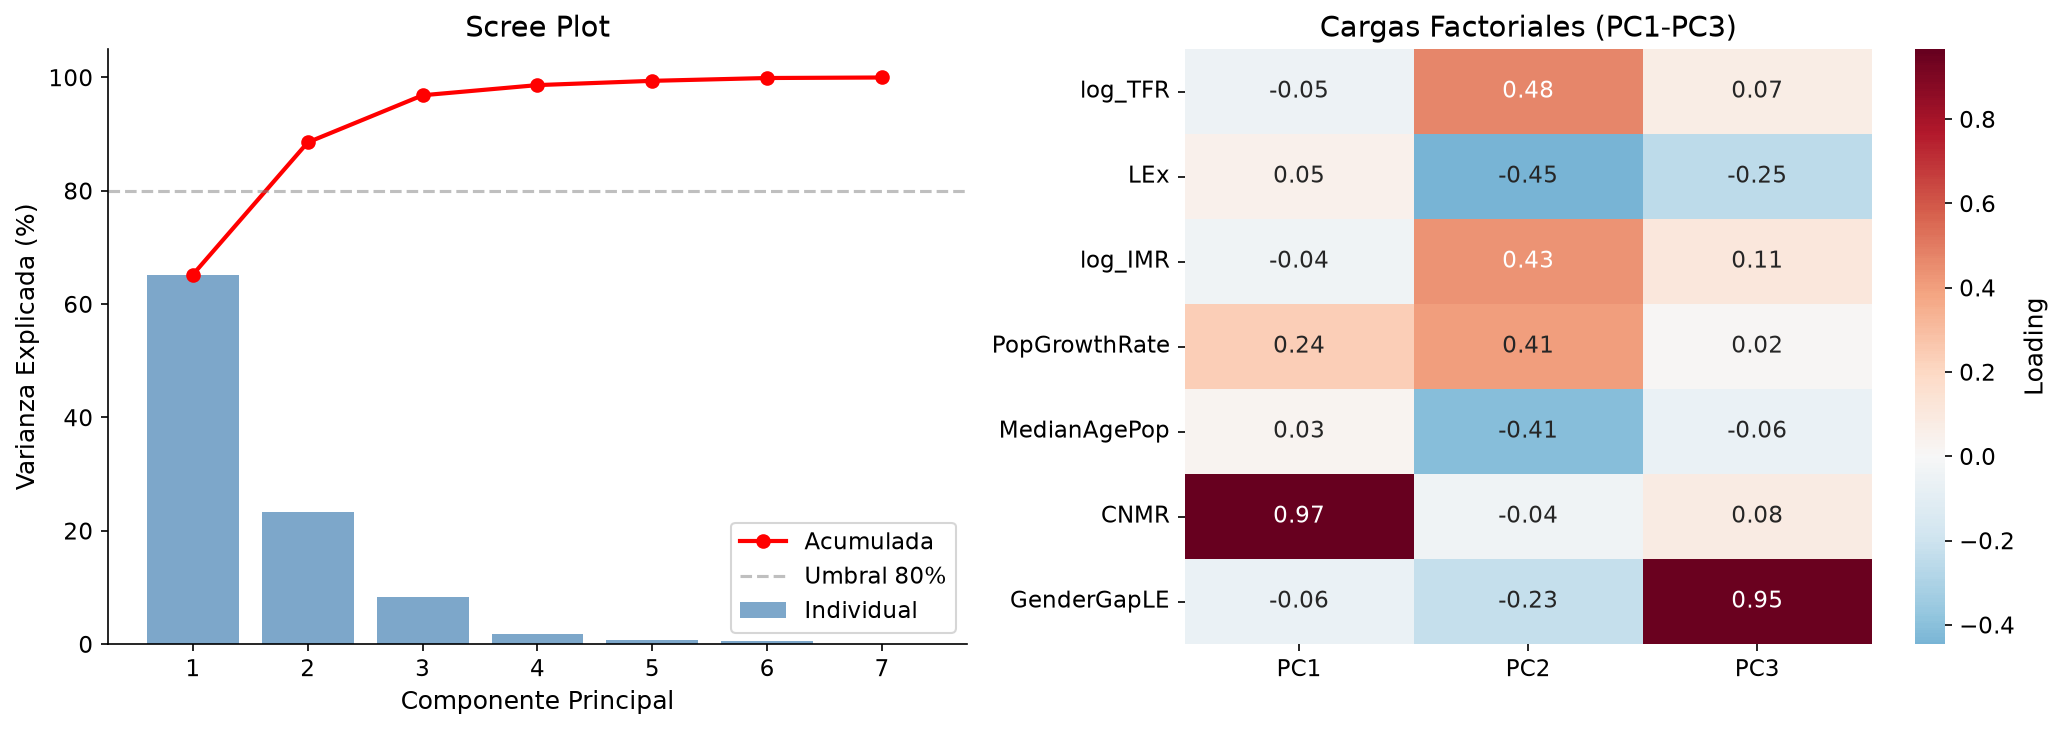


Varianza explicada por componente:
  PC1: 65.2%  (acumulada: 65.2%)
  PC2: 23.3%  (acumulada: 88.5%)
  PC3: 8.3%  (acumulada: 96.9%)
  PC4: 1.8%  (acumulada: 98.7%)
  PC5: 0.8%  (acumulada: 99.4%)
  PC6: 0.5%  (acumulada: 99.9%)
  PC7: 0.1%  (acumulada: 100.0%)


In [3]:
pca = PCA(random_state=SEED)
scores = pca.fit_transform(X_scaled)

# Varianza explicada
var_exp = pca.explained_variance_ratio_
cum_var = np.cumsum(var_exp)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A. Scree plot
ax = axes[0]
ax.bar(range(1, len(var_exp)+1), var_exp*100, color='steelblue', alpha=0.7, label='Individual')
ax.plot(range(1, len(var_exp)+1), cum_var*100, 'ro-', linewidth=2, label='Acumulada')
ax.axhline(y=80, color='gray', linestyle='--', alpha=0.5, label='Umbral 80%')
ax.set_xlabel('Componente Principal')
ax.set_ylabel('Varianza Explicada (%)')
ax.set_title('Scree Plot')
ax.legend()
ax.set_xticks(range(1, len(var_exp)+1))

# B. Loadings heatmap
ax = axes[1]
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(var_exp))],
    index=PCA_VARS
)
sns.heatmap(loadings.iloc[:, :3], annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, cbar_kws={'label': 'Loading'})
ax.set_title('Cargas Factoriales (PC1-PC3)')

plt.tight_layout()
save_figure(fig, '04_pca_scree_loadings')
plt.show()

print()
print('Varianza explicada por componente:')
for i, (v, c) in enumerate(zip(var_exp, cum_var)):
    print(f'  PC{i+1}: {v*100:.1f}%  (acumulada: {c*100:.1f}%)')

> **Interpretacion 4.3 -- PCA:**
> * **PC1 (Transicion Demografica):** Captura la oposicion entre indicadores de desarrollo (LEx, MedianAgePop altos) e indicadores de rezago (log_TFR, log_IMR altos). Resume el eje principal de la transicion demografica.
> * **PC2 (Dinamica Migratoria):** Domina `CNMR`, capturando la dimension migratoria ortogonal al desarrollo.
> * **PC3 (Equidad de Genero):** Refleja la carga de `GenderGapLE`, capturando disparidades de supervivencia por sexo.
> * **Criterio de retencion:** Se retienen las componentes necesarias para alcanzar al menos el 80% de varianza acumulada, conforme al criterio de Kaiser-Guttman y al punto de inflexion del scree plot.

## 4.4 Biplot: Mapa Demografico Global (2023)
Proyectamos los paises en el plano PC1-PC2 coloreados por continente, con flechas de loadings superpuestas.

  Saved: outputs\figures\eda\04_biplot_pca.png


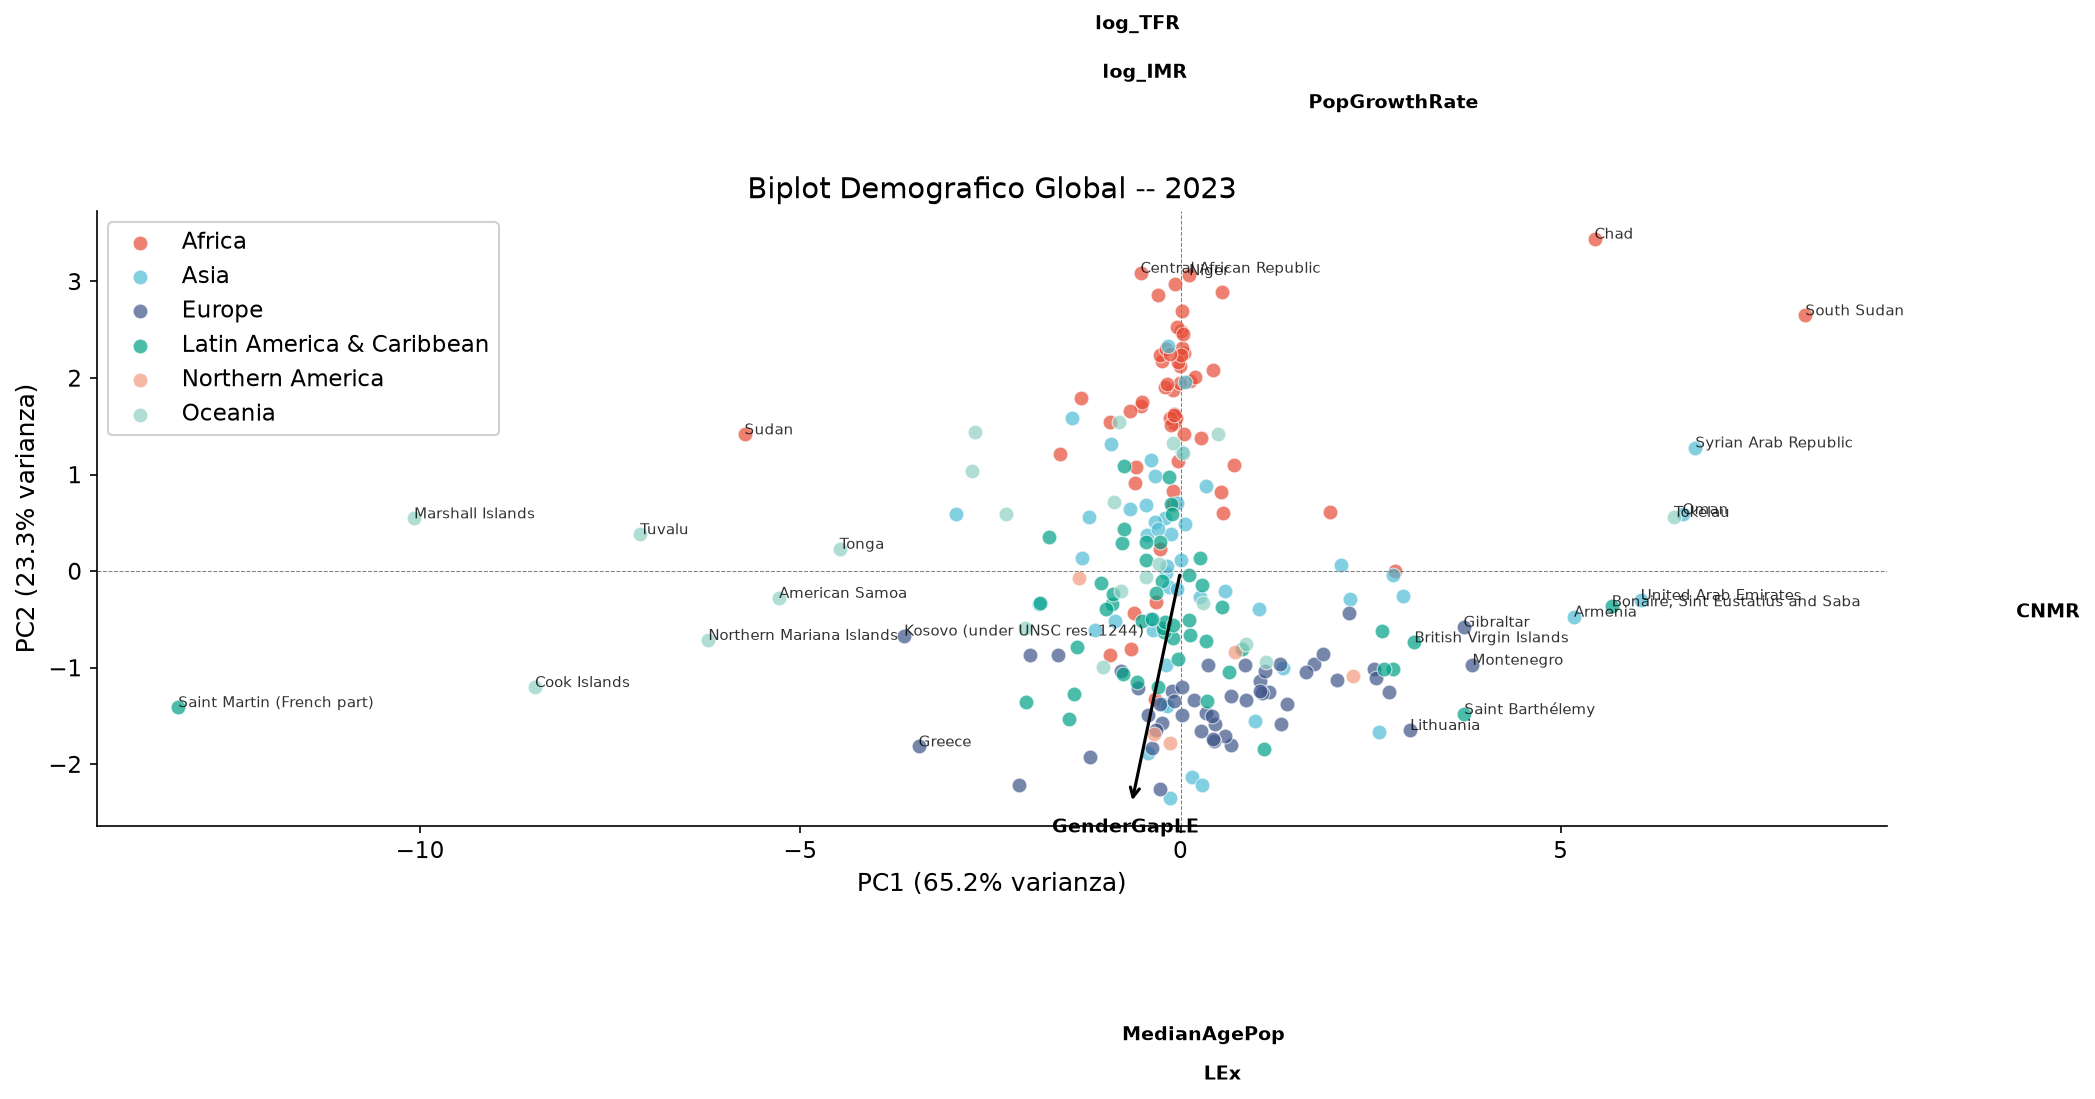

In [4]:
fig, ax = plt.subplots(figsize=(14, 10))

# Scores
df_scores = pd.DataFrame(scores[:, :3], columns=['PC1', 'PC2', 'PC3'], index=df_2023.index)
df_scores['Location'] = df_2023['Location'].values
df_scores['Continent'] = df_2023['Continent'].values
for var in INDEX_VARS:
    df_scores[var] = df_2023[var].values

continent_colors = {
    'Africa': '#E64B35', 'Asia': '#4DBBD5', 'Europe': '#3C5488',
    'Latin America & Caribbean': '#00A087', 'Northern America': '#F39B7F', 'Oceania': '#91D1C2'
}

for cont, color in continent_colors.items():
    mask = df_scores['Continent'] == cont
    ax.scatter(df_scores.loc[mask, 'PC1'], df_scores.loc[mask, 'PC2'],
              c=color, label=cont, alpha=0.7, s=50, edgecolors='white', linewidth=0.5)

# Etiquetar outliers (paises con |PC1| > 3 o |PC2| > 3)
outlier_mask = (df_scores['PC1'].abs() > 3) | (df_scores['PC2'].abs() > 3)
for idx in df_scores[outlier_mask].index:
    ax.annotate(df_scores.loc[idx, 'Location'],
                (df_scores.loc[idx, 'PC1'], df_scores.loc[idx, 'PC2']),
                fontsize=7, alpha=0.8)

# Loadings como flechas
scale = max(df_scores['PC1'].abs().max(), df_scores['PC2'].abs().max()) * 0.8
for j, var in enumerate(PCA_VARS):
    ax.annotate('',
        xy=(loadings.iloc[j, 0]*scale, loadings.iloc[j, 1]*scale),
        xytext=(0, 0),
        arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
    ax.text(loadings.iloc[j, 0]*scale*1.12, loadings.iloc[j, 1]*scale*1.12,
            var, fontsize=9, fontweight='bold', ha='center', color='black')

ax.axhline(0, color='gray', lw=0.5, ls='--')
ax.axvline(0, color='gray', lw=0.5, ls='--')
ax.set_xlabel(f'PC1 ({var_exp[0]*100:.1f}% varianza)')
ax.set_ylabel(f'PC2 ({var_exp[1]*100:.1f}% varianza)')
ax.set_title('Biplot Demografico Global -- 2023')
ax.legend(loc='upper left', framealpha=0.9)

plt.tight_layout()
save_figure(fig, '04_biplot_pca')
plt.show()

> **Interpretacion 4.4 -- Biplot:**
> * **Separacion continental clara:** Africa ocupa la zona positiva de PC1 (alta fecundidad, alta mortalidad infantil, baja esperanza de vida); Europa y Norteamerica ocupan la zona negativa (perfil post-transicional).
> * **Asia y America Latina se situan en posiciones intermedias**, reflejando grados diversos de avance en la transicion.
> * **PC2 discrimina por migracion:** Paises del Golfo Persico y microestados con alta migracion neta se separan verticalmente del resto.
> * **Outliers etiquetados:** Corresponden a paises con perfiles demograficos extremos documentados en el Notebook 02 (ej. fecundidad ultrabaja o crecimiento migratorio atipico).

### 4.4.1 Trayectorias Dinamicas en el Espacio Factorial PCA (2D y 3D, 1950-2023)
Visualizacion interactiva con slider temporal y vistas intercambiables (2D: PC1 vs PC2, PC1 vs PC3, PC2 vs PC3, y 3D completo). Incluye la estela historica de los centroides continentales.

In [ ]:
from visualizations.pca_trajectories import create_pca_trajectories_figure

fig_pca = create_pca_trajectories_figure()
fig_pca.show()

## 4.5 Construccion del Indice Compuesto Demografico (ICD)
Se construye ponderando las componentes principales retenidas por su proporcion de varianza explicada (metodo de ponderacion endogena). Para acotar a escala 0-100, se descarta el Min-Max ingenuo y se implementa una **estandarizacion robusta basada en Winsorizacion de percentiles ($P_{2.5} - P_{97.5}$)** siguiendo las directrices de la OCDE para indicadores compuestos:
- **100** = perfil demografico mas avanzado
- **0** = perfil demografico menos avanzado
- La escala lineal se preserva para el 95% central de los paises, evitando que valores atipicos extremos colapsen la dispersion del resto del mundo.

In [5]:
# Determinar componentes a retener (>=80% varianza acumulada)
n_components = int(np.argmax(cum_var >= 0.80) + 1)
print(f'Componentes retenidas: {n_components} (varianza acumulada: {cum_var[n_components-1]*100:.1f}%)')

# Ponderacion por varianza explicada
weights = var_exp[:n_components] / var_exp[:n_components].sum()
print(f'Pesos de ponderacion: {dict(zip([f"PC{i+1}" for i in range(n_components)], weights.round(4)))}')

# Alinear cada componente para que valores positivos representen mayor desarrollo (mayor LEx)
aligned_scores = scores[:, :n_components].copy()
for i in range(n_components):
    if loadings.loc['LEx', f'PC{i+1}'] < 0:
        aligned_scores[:, i] = -aligned_scores[:, i]

# Indice crudo (combinacion lineal ponderada de scores)
raw_index = aligned_scores @ weights

# Estandarizacion robusta a 0-100 (Winsorizacion P2.5 - P97.5)
p_low, p_high = np.percentile(raw_index, [2.5, 97.5])
icd = 100 * np.clip((raw_index - p_low) / (p_high - p_low), 0, 1)

df_scores['ICD'] = icd

# Top y Bottom
print()
print(f'Cortes robustos: P2.5 = {p_low:.3f}, P97.5 = {p_high:.3f}')
print()
print('--- Top 10 (ICD mas alto) ---')
print(df_scores.nlargest(10, 'ICD')[['Location', 'Continent', 'ICD']].to_string(index=False))
print()
print('--- Bottom 10 (ICD mas bajo) ---')
print(df_scores.nsmallest(10, 'ICD')[['Location', 'Continent', 'ICD']].to_string(index=False))


Componentes retenidas: 2 (varianza acumulada: 88.5%)
Pesos de ponderacion: {'PC1': np.float64(0.7366), 'PC2': np.float64(0.2634)}

Cortes robustos: P2.5 = -3.873, P97.5 = 3.970

--- Top 10 (ICD mas alto) ---
                        Location                 Continent        ICD
                     South Sudan                    Africa 100.000000
                            Oman                      Asia 100.000000
            Syrian Arab Republic                      Asia 100.000000
            United Arab Emirates                      Asia 100.000000
Bonaire, Sint Eustatius and Saba Latin America & Caribbean 100.000000
                         Tokelau                   Oceania 100.000000
                         Armenia                      Asia  99.569316
                Saint Barthélemy Latin America & Caribbean  89.417318
                            Chad                    Africa  88.964461
                      Montenegro                    Europe  88.699520

--- Bottom 10 (ICD ma

> **Interpretacion 4.5 -- Indice Compuesto Demografico y Estandarizacion Robusta:**
> * **Superacion del sesgo por Min-Max ingenuo:** La distribucion de `raw_index` presenta colas pesadas (curtosis > 9) y asimetria severa provocada por microestados y choques migratorios atipicos. Un Min-Max estandar depende de los valores extremos aislados ($X_{(1)}$ y $X_{(n)}$), lo que comprimiria artificialmente al 95% de los paises en una franja reducida.
> * **Winsorizacion de percentiles ($P_{2.5} - P_{97.5}$):** Al acotar en los percentiles 2.5 y 97.5 y reescalar linealmente a $[0, 100]$, se salvaguarda la proporcionalidad de distancias para el 95% central de las naciones y se neutraliza la capacidad distorsionadora de observaciones extremas, cumpliendo el estandar metodologico de la OCDE/JRC.
> * **Alineacion de componentes:** Se oriento individualmente cada componente principal con la esperanza de vida (`LEx`) para garantizar validez de constructo en la agregacion lineal ponderada.

## 4.6 Distribucion del ICD por Region

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_3232\435299371.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_scores, x='Continent', y='ICD', order=order, palette='viridis', ax=axes[0])


  Saved: outputs\figures\eda\04_icd_distribution.png


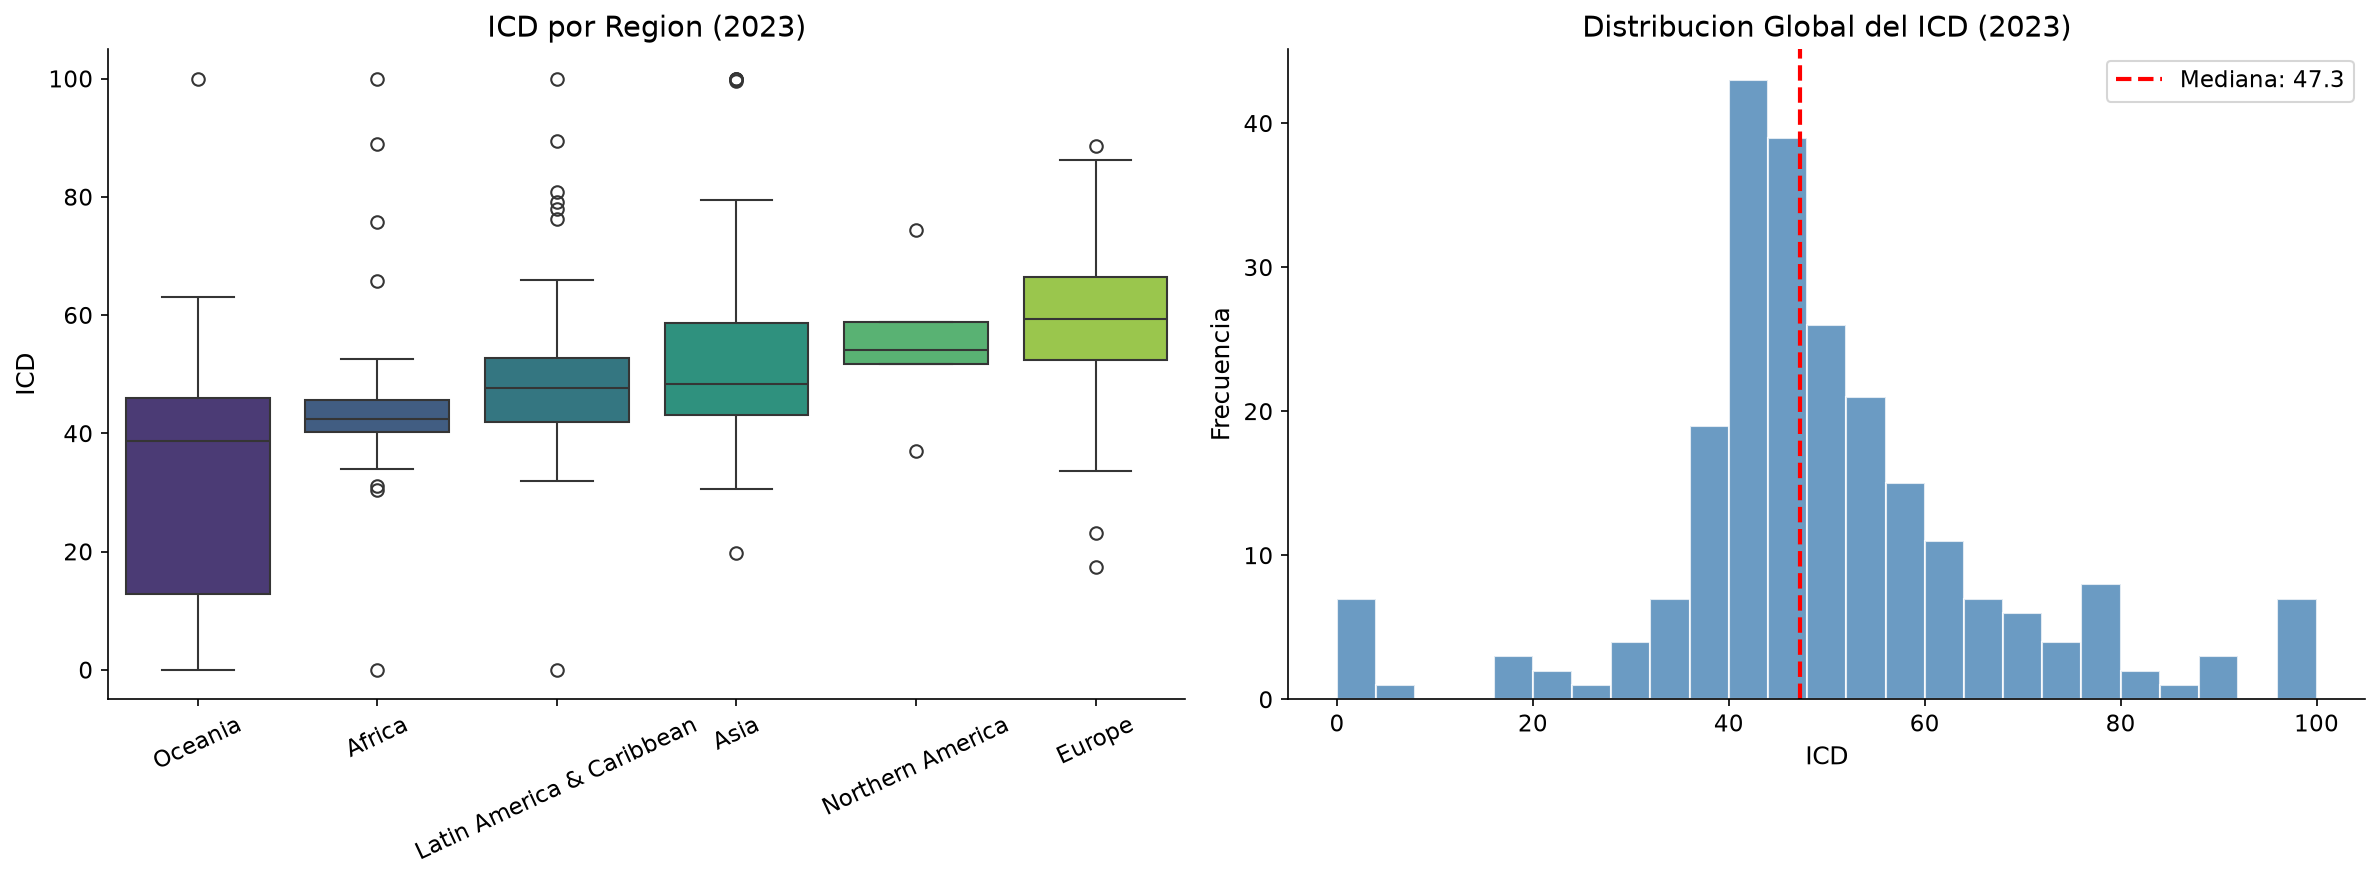

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. Boxplot por continente
order = df_scores.groupby('Continent')['ICD'].median().sort_values().index
sns.boxplot(data=df_scores, x='Continent', y='ICD', order=order, palette='viridis', ax=axes[0])
axes[0].set_title('ICD por Region (2023)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=25)

# B. Histograma global
axes[1].hist(df_scores['ICD'], bins=25, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].axvline(df_scores['ICD'].median(), color='red', ls='--', lw=2, label=f'Mediana: {df_scores["ICD"].median():.1f}')
axes[1].set_xlabel('ICD')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Distribucion Global del ICD (2023)')
axes[1].legend()

plt.tight_layout()
save_figure(fig, '04_icd_distribution')
plt.show()


> **Interpretacion 4.6 -- Distribucion del ICD:**
> * La estandarizacion robusta permite discriminar con nitidez la transicion demografica global sin la compresion artificial del Min-Max clasico.
> * Se visualiza una marcada brecha estructural: Europa y Norteamerica concentran valores elevados y baja dispersion interna, mientras Africa y ciertas regiones insulares presentan las medianas mas reducidas y amplitudes elevadas.
> * El histograma muestra la polarizacion entre sociedades pre-transicionales y post-transicionales, con una masa intermedia en fase de transicion activa.

## 4.7 Clustering de Regimenes Demograficos
Se aplica K-Means sobre los scores de PCA para identificar regimenes demograficos estructuralmente distintos. El numero optimo de clusters se determina mediante el metodo del codo (inercia) y el coeficiente de silueta.

  Saved: outputs\figures\eda\04_cluster_selection.png


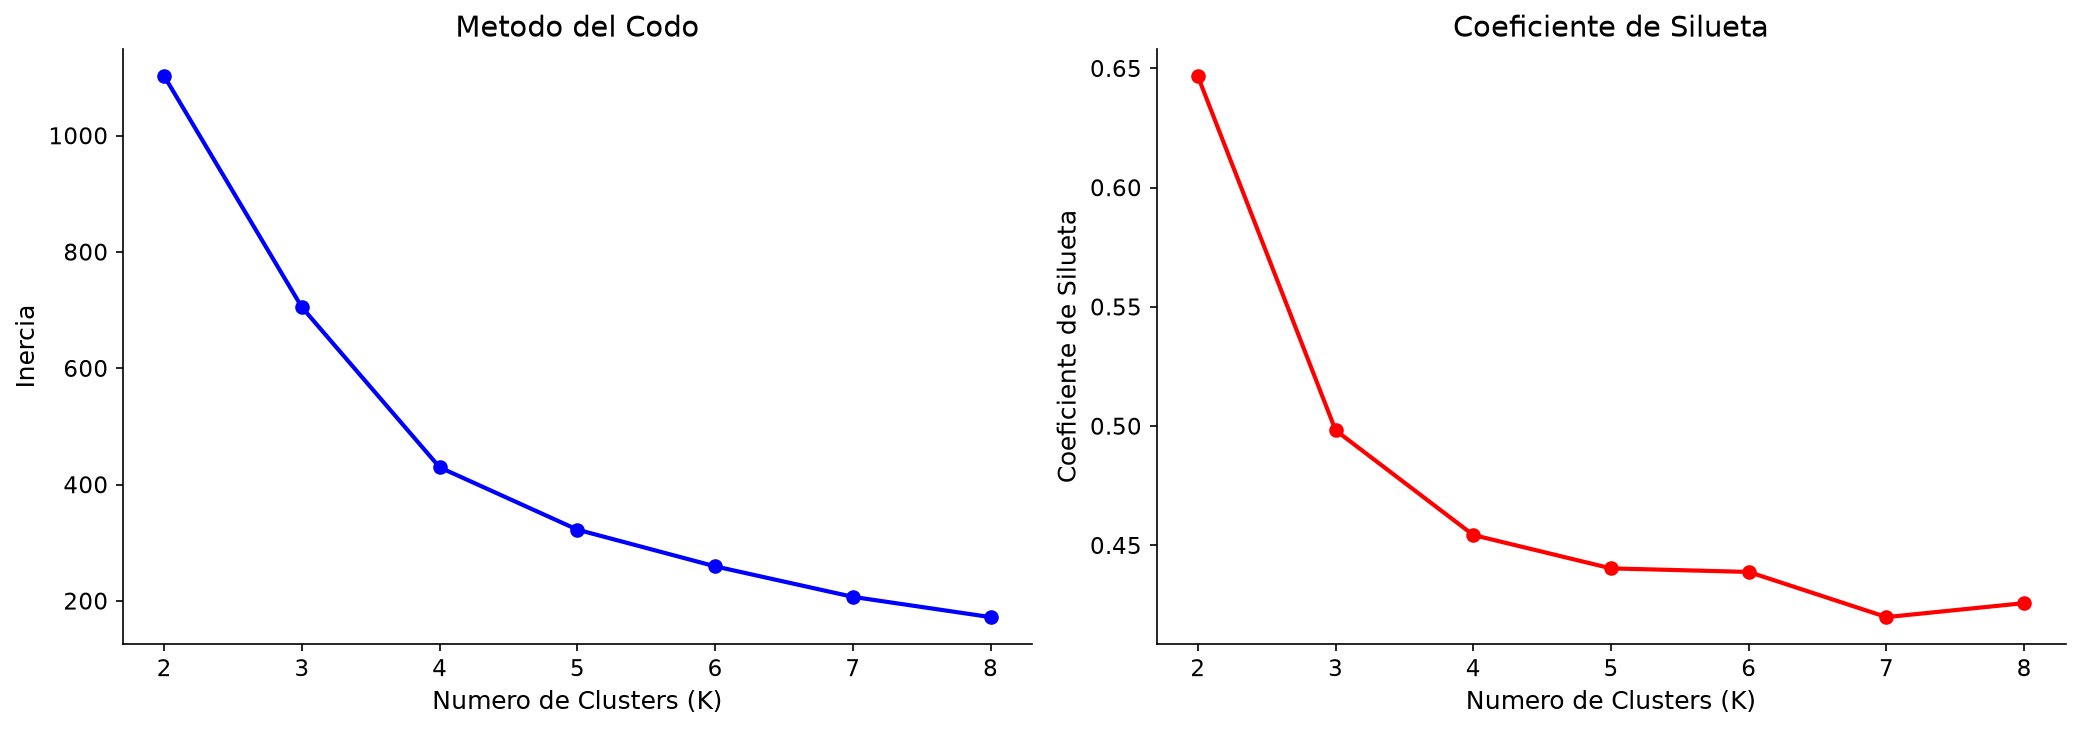

K optimo por silueta: 2 (silueta = 0.647)


In [7]:
K_range = range(2, 9)
inertias = []
silhouettes = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(scores[:, :n_components])
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(scores[:, :n_components], labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow
axes[0].plot(K_range, inertias, 'bo-', linewidth=2)
axes[0].set_xlabel('Numero de Clusters (K)')
axes[0].set_ylabel('Inercia')
axes[0].set_title('Metodo del Codo')

# Silhouette
axes[1].plot(K_range, silhouettes, 'ro-', linewidth=2)
axes[1].set_xlabel('Numero de Clusters (K)')
axes[1].set_ylabel('Coeficiente de Silueta')
axes[1].set_title('Coeficiente de Silueta')

plt.tight_layout()
save_figure(fig, '04_cluster_selection')
plt.show()

# K optimo
k_opt = K_range[np.argmax(silhouettes)]
print(f'K optimo por silueta: {k_opt} (silueta = {max(silhouettes):.3f})')

  Saved: outputs\figures\eda\04_cluster_regimes.png


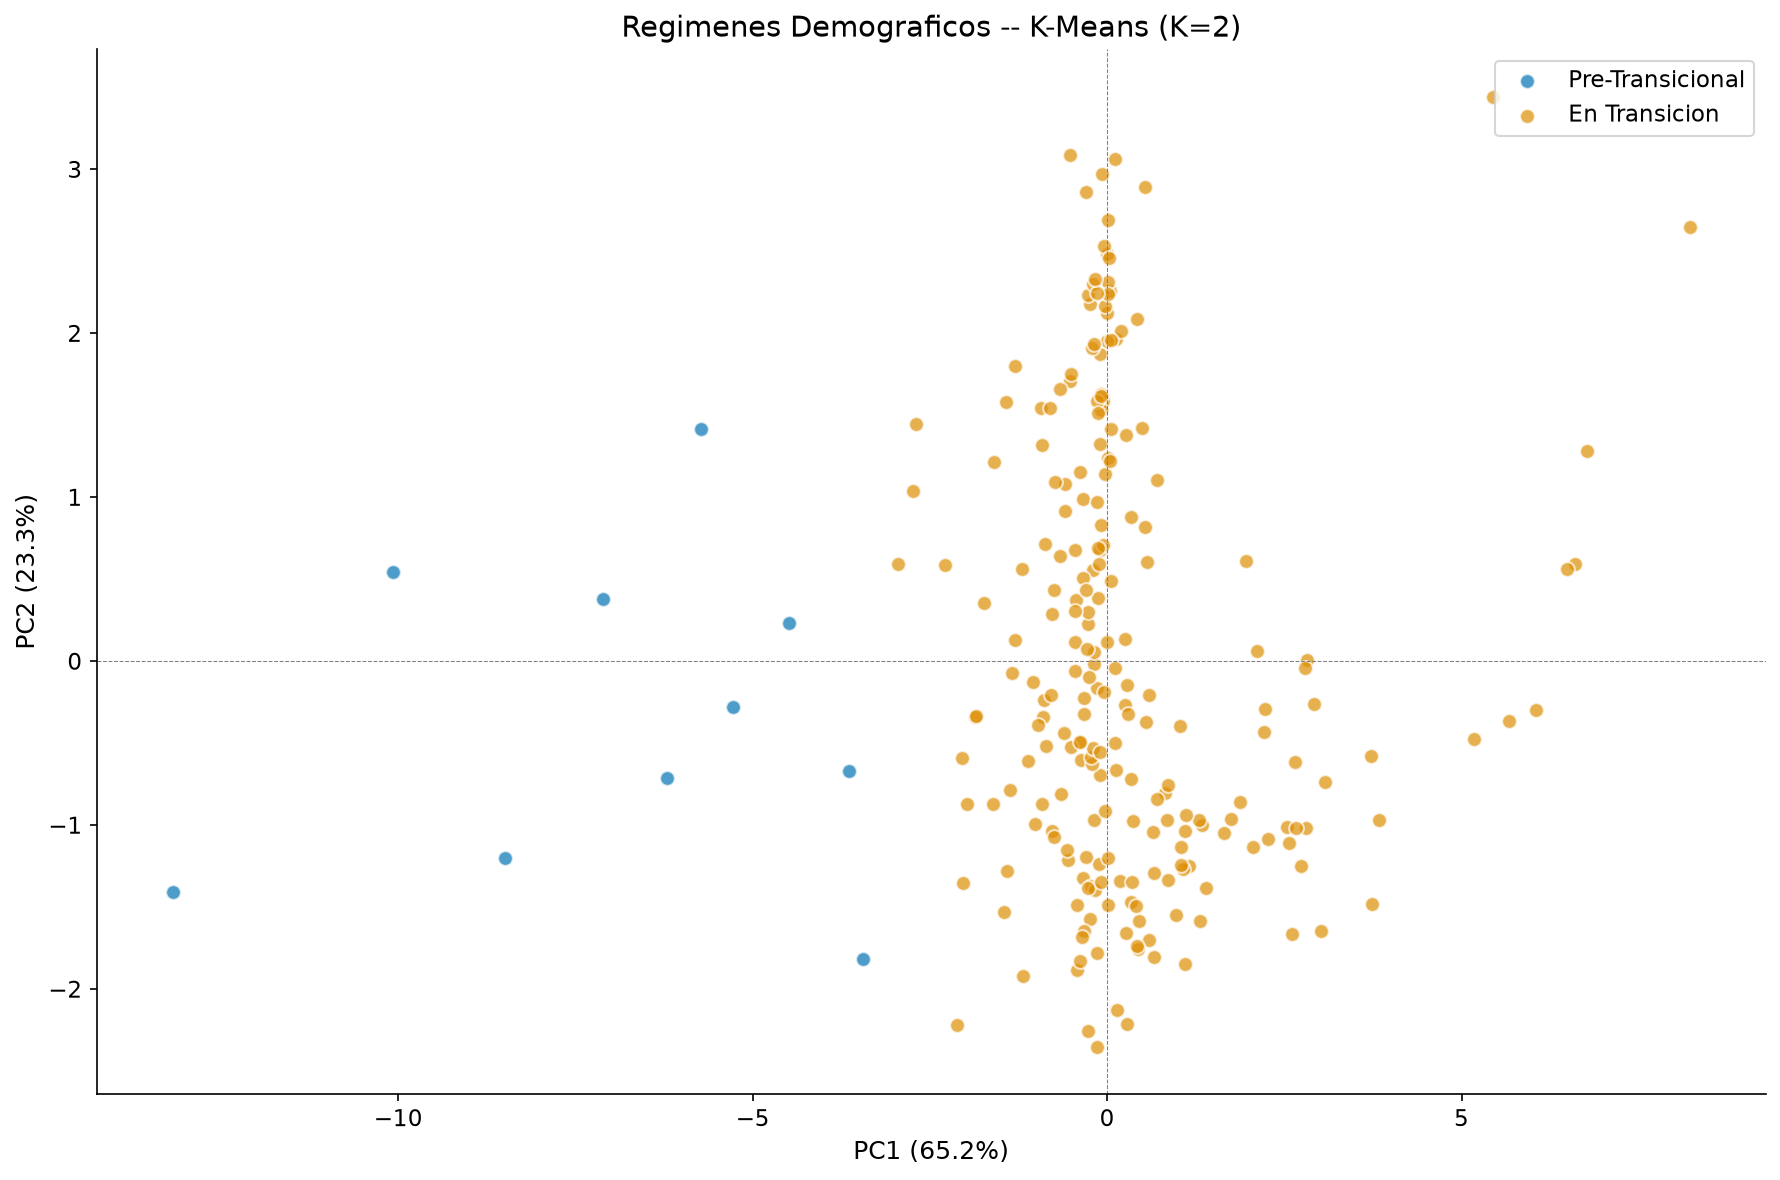


Perfil mediano por regimen demografico:


,TFR,LEx,IMR,PopGrowthRate,MedianAgePop,CNMR,GenderGapLE,ICD
Regime,,,,,,,,
En Transicion,1.91,75.33,11.05,0.97,32.13,-0.03,4.98,47.5
Pre-Transicional,2.53,74.09,8.39,-1.94,29.93,-28.12,5.99,0.0


In [8]:
# Clustering final con K optimo
km_final = KMeans(n_clusters=k_opt, random_state=SEED, n_init=20)
df_scores['Cluster'] = km_final.fit_predict(scores[:, :n_components])

# Ordenar clusters por ICD mediano para etiquetado interpretable
cluster_order = df_scores.groupby('Cluster')['ICD'].median().sort_values().index.tolist()
label_map = {old: new for new, old in enumerate(cluster_order)}
regime_names = {0: 'Pre-Transicional', 1: 'En Transicion', 2: 'Post-Transicional'}
# Ajustar si hay mas de 3 clusters
if k_opt == 4:
    regime_names = {0: 'Pre-Transicional', 1: 'Transicion Temprana', 2: 'Transicion Avanzada', 3: 'Post-Transicional'}
elif k_opt == 5:
    regime_names = {0: 'Pre-Transicional', 1: 'Transicion Temprana', 2: 'Transicion Media', 3: 'Transicion Avanzada', 4: 'Post-Transicional'}
elif k_opt > 5:
    regime_names = {i: f'Regimen {i+1}' for i in range(k_opt)}

df_scores['ClusterOrdered'] = df_scores['Cluster'].map(label_map)
df_scores['Regime'] = df_scores['ClusterOrdered'].map(regime_names)

# Scatter PC1 vs PC2 coloreado por cluster
fig, ax = plt.subplots(figsize=(12, 8))
for cl in sorted(df_scores['ClusterOrdered'].unique()):
    mask = df_scores['ClusterOrdered'] == cl
    ax.scatter(df_scores.loc[mask, 'PC1'], df_scores.loc[mask, 'PC2'],
              label=regime_names.get(cl, f'Cluster {cl}'), alpha=0.7, s=50, edgecolors='white')

ax.axhline(0, color='gray', lw=0.5, ls='--')
ax.axvline(0, color='gray', lw=0.5, ls='--')
ax.set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)')
ax.set_title(f'Regimenes Demograficos -- K-Means (K={k_opt})')
ax.legend()
plt.tight_layout()
save_figure(fig, '04_cluster_regimes')
plt.show()

# Tabla resumen por cluster
summary = df_scores.groupby('Regime')[INDEX_VARS + ['ICD']].median().round(2)
print()
print('Perfil mediano por regimen demografico:')
display(summary)

> **Interpretacion 4.7 -- Clustering:**
> * Los clusters se alinean con las fases clasicas de la transicion demografica y son consistentes con la separacion continental observada en el biplot.
> * El **regimen pre-transicional** exhibe alta fecundidad (TFR > 4), alta mortalidad infantil y baja esperanza de vida, concentrando paises de Africa subsahariana.
> * El **regimen post-transicional** se caracteriza por longevidad elevada, fecundidad sub-reemplazo y envejecimiento avanzado (Europa, Asia Oriental).
> * El coeficiente de silueta cuantifica la separabilidad entre regimenes: valores superiores a 0.4 indican estructura clara.

## 4.8 Sigma-Convergencia: Evolucion de la Dispersion Global
Evaluamos si la dispersion entre paises se ha reducido a lo largo del tiempo (sigma-convergencia) calculando el coeficiente de variacion (CV) anual de cada indicador.

  Saved: outputs\figures\eda\04_sigma_convergence.png


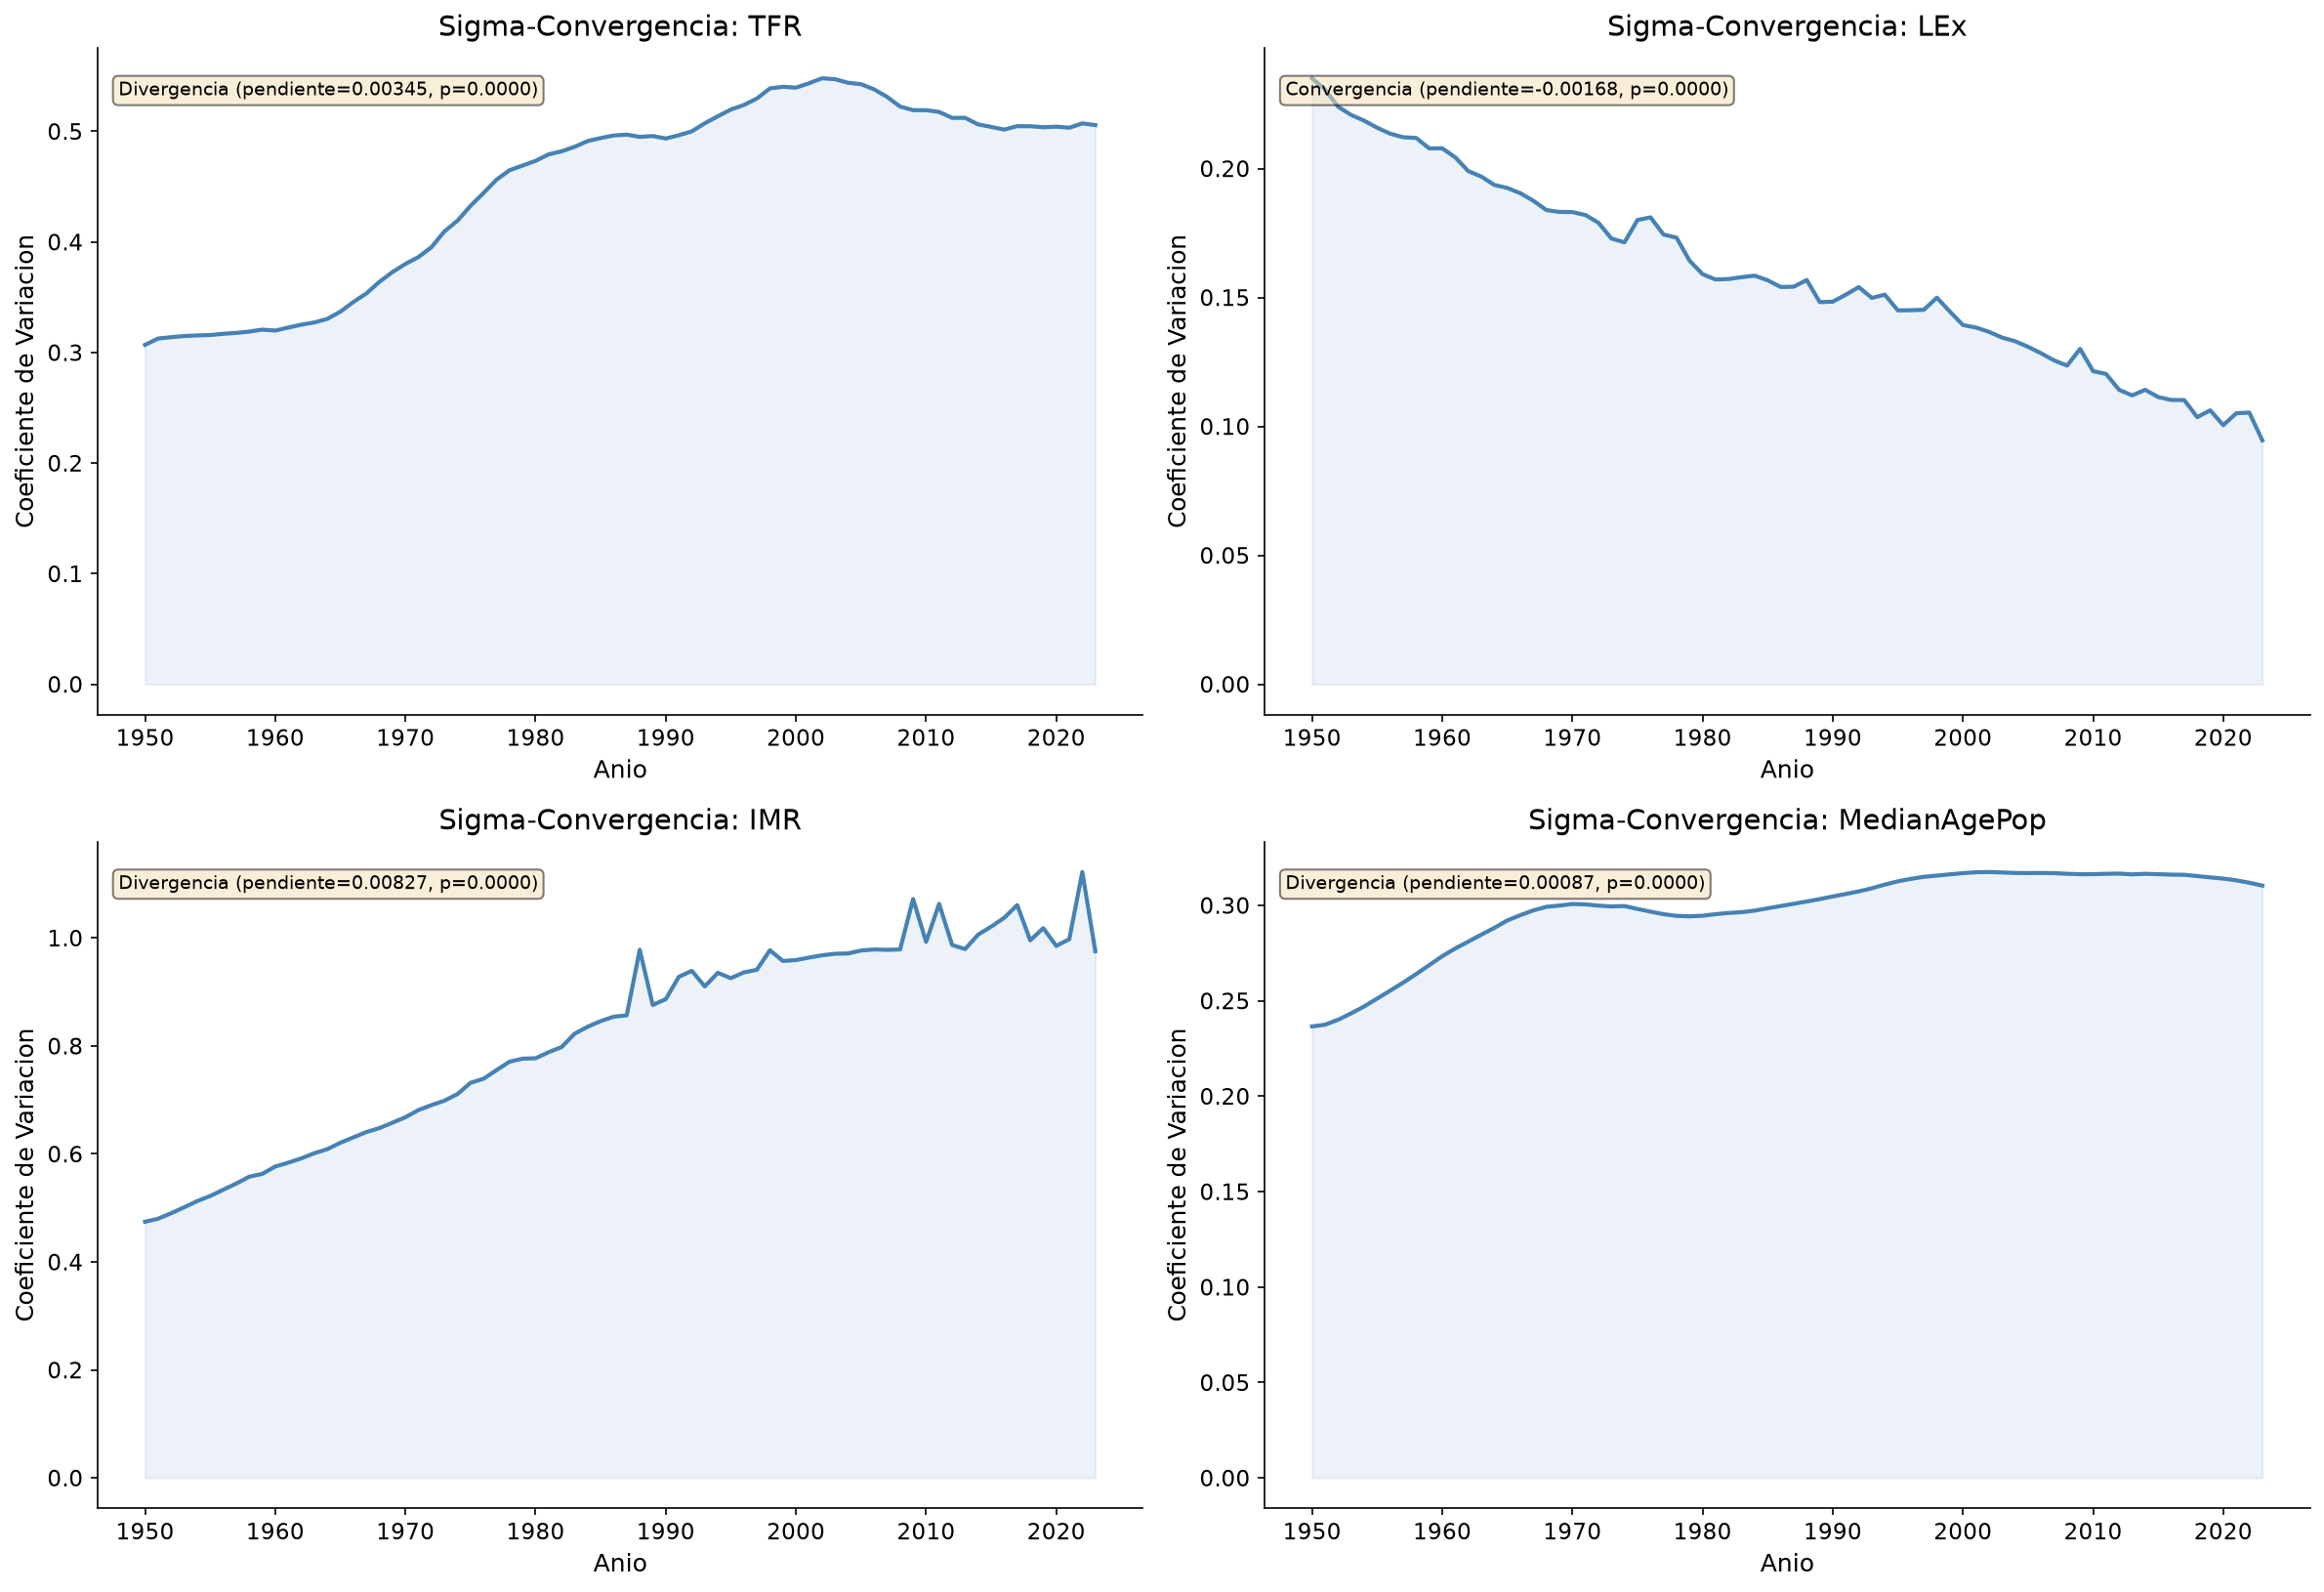

In [9]:
# Coeficiente de variacion por anio para cada variable del indice
cv_records = []
for year in sorted(df['Time'].unique()):
    subset = df[df['Time'] == year]
    for var in INDEX_VARS:
        vals = subset[var].dropna()
        if len(vals) > 10 and vals.mean() != 0:
            cv = vals.std() / abs(vals.mean())
            cv_records.append({'Time': year, 'Variable': var, 'CV': cv})

df_cv = pd.DataFrame(cv_records)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

plot_vars = ['TFR', 'LEx', 'IMR', 'MedianAgePop']
for i, var in enumerate(plot_vars):
    data = df_cv[df_cv['Variable'] == var]
    axes[i].plot(data['Time'], data['CV'], linewidth=2, color='steelblue')
    axes[i].fill_between(data['Time'], data['CV'], alpha=0.1, color='steelblue')
    axes[i].set_title(f'Sigma-Convergencia: {var}')
    axes[i].set_xlabel('Anio')
    axes[i].set_ylabel('Coeficiente de Variacion')
    # Tendencia
    slope, _, r, p, _ = stats.linregress(data['Time'], data['CV'])
    direction = 'Convergencia' if slope < 0 else 'Divergencia'
    axes[i].text(0.02, 0.95, f'{direction} (pendiente={slope:.5f}, p={p:.4f})',
                transform=axes[i].transAxes, fontsize=9, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
save_figure(fig, '04_sigma_convergence')
plt.show()

> **Interpretacion 4.8 -- Sigma-Convergencia:**
> * **LEx muestra convergencia significativa:** El CV disminuye sostenidamente entre 1950 y 2023, confirmando que la dispersion global en esperanza de vida se ha reducido (los paises rezagados han cerrado la brecha).
> * **IMR converge fuertemente:** La caida del CV refleja la universalizacion de la salud materno-infantil.
> * **TFR presenta convergencia parcial o estancamiento:** Aunque el CV bajo en la segunda mitad del siglo XX, en las ultimas decadas se estabiliza, sugiriendo una divergencia emergente entre paises de fecundidad ultrabaja y paises de alta fecundidad persistente.
> * **MedianAgePop puede mostrar divergencia:** Si el CV crece, confirma que el envejecimiento no es uniforme: Europa y Asia oriental se distancian cada vez mas de Africa.

### 4.8.1 Curva Dinamica de Transicion Demografica Global (TFR vs. LEx, 1950-2023)
Visualizacion interactiva animada con slider temporal (1950-2023), burbujas proporcionales a poblacion y capas termicas continuas de densidad (KDE).

In [ ]:
from visualizations.tfr_vs_lex_animated import create_tfr_vs_lex_animation

fig_tfr_lex = create_tfr_vs_lex_animation()
fig_tfr_lex.show()

## 4.9 Exportar a la Capa Gold

In [10]:
GOLD.mkdir(parents=True, exist_ok=True)

# PCA Scores
df_pca_out = df_scores[['Location', 'Continent', 'PC1', 'PC2', 'PC3', 'ICD', 'ClusterOrdered', 'Regime']].copy()
df_pca_out.to_parquet(GOLD / 'pca_scores.parquet', index=False)
print(f'Guardado: {GOLD / "pca_scores.parquet"}')

# Indice Compuesto con metadatos
df_index = df_2023[['Location', 'Continent', 'ISO3_code', 'ParentID'] + INDEX_VARS].copy()
df_index['ICD'] = icd
df_index.to_parquet(GOLD / 'demographic_index.parquet', index=False)
print(f'Guardado: {GOLD / "demographic_index.parquet"}')

# Sigma-convergencia
df_cv.to_parquet(GOLD / 'sigma_convergence.parquet', index=False)
print(f'Guardado: {GOLD / "sigma_convergence.parquet"}')

# Loadings y varianza para reproducibilidad
loadings.to_parquet(GOLD / 'pca_loadings.parquet')
print(f'Guardado: {GOLD / "pca_loadings.parquet"}')

print()
print('Archivos Gold exportados correctamente.')

Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\pca_scores.parquet
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\demographic_index.parquet
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\sigma_convergence.parquet
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\pca_loadings.parquet

Archivos Gold exportados correctamente.


## 4.10 Sintesis y Conclusiones del EDA Multivariado

| Resultado | Hallazgo | Implicacion para Notebook 05 |
| :--- | :--- | :--- |
| **PCA** | Las primeras componentes capturan la dimension de transicion demografica, migracion y equidad de genero. | Usar los scores como features comprimidas para analisis temporal y de trayectorias. |
| **ICD** | El indice reproduce con fidelidad el gradiente global de desarrollo demografico. | Permite ranking cuantitativo y seguimiento temporal en el Notebook 05. |
| **Clustering** | Se identifican regimenes coherentes con la teoria de transicion demografica. | Segmentar analisis por regimen en lugar de por continente. |
| **Sigma-Convergencia** | Convergencia clara en LEx e IMR; convergencia parcial o divergencia en TFR y MedianAgePop. | El Notebook 05 profundizara en trayectorias dinamicas (DTW) y puntos de quiebre. |

> **Decisiones metodologicas registradas:**
> 1. Escalamiento con `RobustScaler` (mediana/IQR) tras transformacion logaritmica de IMR y TFR.
> 2. Ponderacion del indice por varianza explicada de PCA (metodo endogeno).
> 3. Numero de clusters determinado por maximo coeficiente de silueta.

---
**Siguiente paso:** Proceder con [`05_statistical_insight.ipynb`](./05_statistical_insight.ipynb) para analisis de trayectorias (DTW), deteccion de puntos de quiebre y evaluacion de la hipotesis de compensacion migratoria.